<a href="https://colab.research.google.com/github/KeshavGoyal-dot/UCS420-Cognitive-Computing/blob/main/UCS420_Assignment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Cognitive Computing — Lab Assignment 8


## Q1. Text preprocessing and word frequency


Original paragraph:
 Artificial intelligence is one of my favourite areas of technology. It helps computers learn from data and solve problems that once required human effort. I find machine learning especially interesting because it can identify patterns in large datasets. AI is used in healthcare, education, transport, and many other fields. When it is developed responsibly, this technology can make everyday tasks faster and more accessible. I enjoy learning about AI because it combines creativity, mathematics, and practical problem solving.

Lowercase text without punctuation:
 artificial intelligence is one of my favourite areas of technology it helps computers learn from data and solve problems that once required human effort i find machine learning especially interesting because it can identify patterns in large datasets ai is used in healthcare education transport and many other fields when it is developed responsibly this technology can make everyday tasks faster and more acces

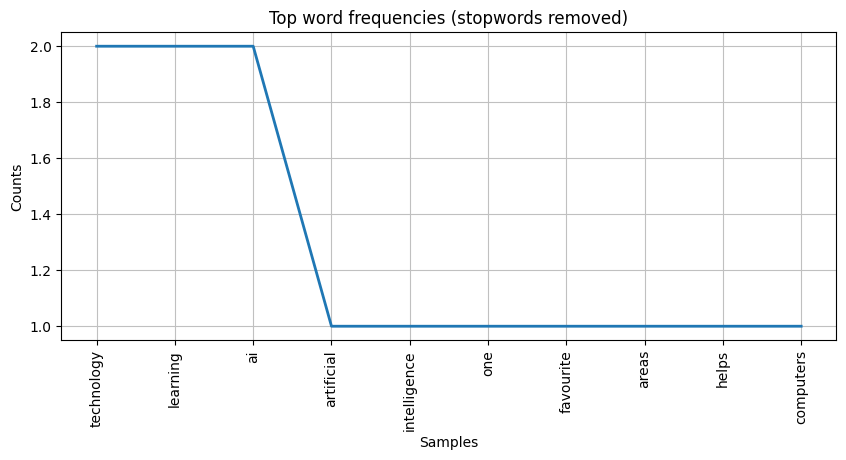

In [12]:
paragraph = (
    "Artificial intelligence is one of my favourite areas of technology. "
    "It helps computers learn from data and solve problems that once required human effort. "
    "I find machine learning especially interesting because it can identify patterns in large datasets. "
    "AI is used in healthcare, education, transport, and many other fields. "
    "When it is developed responsibly, this technology can make everyday tasks faster and more accessible. "
    "I enjoy learning about AI because it combines creativity, mathematics, and practical problem solving."
)

print("Original paragraph:\n", paragraph)

# 1. Convert to lowercase and remove punctuation using re
clean_text = re.sub(r"[^a-zA-Z0-9\s]", "", paragraph.lower())
print("\nLowercase text without punctuation:\n", clean_text)

# 2. Tokenize into words and sentences
word_tokens = word_tokenize(paragraph)
sentence_tokens = sent_tokenize(paragraph)
print("\nWord tokens:", word_tokens)
print("\nSentence tokens:")
for i, sentence in enumerate(sentence_tokens, 1):
    print(f"{i}. {sentence}")

# 3. Compare split() and word_tokenize()
split_tokens = paragraph.split()
nltk_tokens = word_tokenize(paragraph)
print("\nPython split():", split_tokens)
print("\nNLTK word_tokenize():", nltk_tokens)
print("\nComparison:")
print("split() separates text mainly at whitespace, so punctuation remains attached to words.")
print("word_tokenize() separates punctuation into individual tokens and handles common language tokenization rules.")

# 4. Remove stopwords
tokens_no_stopwords = [
    token for token in word_tokenize(clean_text)
    if token not in stop_words and token.isalpha()
]
print("\nTokens after stopword removal:", tokens_no_stopwords)

# 5. Word frequency distribution (excluding stopwords)
frequency = FreqDist(tokens_no_stopwords)
print("\nWord frequency distribution:")
for word, count in frequency.most_common():
    print(f"{word}: {count}")

plt.figure(figsize=(10, 4))
frequency.plot(10, title="Top word frequencies (stopwords removed)")
plt.show()

## Q2. Feature extraction: stemming and lemmatization



In [13]:
# 1. Extract alphabet-only words using re.findall()
alphabet_words = re.findall(r"\b[a-zA-Z]+\b", paragraph.lower())
print("Alphabet-only words:", alphabet_words)

# 2. Remove stopwords
filtered_words = [w for w in alphabet_words if w not in stop_words]
print("\nAfter stopword removal:", filtered_words)

# 3. Porter stemming
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_words]

# 4. WordNet lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in filtered_words]

print("\nStemmed words:    ", stemmed_words)
print("Lemmatized words: ", lemmatized_words)

# 5. Compare outputs
print("\nComparison:")
for original, stem, lemma in zip(filtered_words, stemmed_words, lemmatized_words):
    print(f"{original:18} -> stem: {stem:14} | lemma: {lemma}")

print("\nStemming usually chops word endings and may produce non-dictionary forms.")
print("Lemmatization uses vocabulary and linguistic analysis to return a meaningful base form.")
print("I would prefer stemming for quick information retrieval, and lemmatization when readable, linguistically meaningful words are important.")

Alphabet-only words: ['artificial', 'intelligence', 'is', 'one', 'of', 'my', 'favourite', 'areas', 'of', 'technology', 'it', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'problems', 'that', 'once', 'required', 'human', 'effort', 'i', 'find', 'machine', 'learning', 'especially', 'interesting', 'because', 'it', 'can', 'identify', 'patterns', 'in', 'large', 'datasets', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'transport', 'and', 'many', 'other', 'fields', 'when', 'it', 'is', 'developed', 'responsibly', 'this', 'technology', 'can', 'make', 'everyday', 'tasks', 'faster', 'and', 'more', 'accessible', 'i', 'enjoy', 'learning', 'about', 'ai', 'because', 'it', 'combines', 'creativity', 'mathematics', 'and', 'practical', 'problem', 'solving']

After stopword removal: ['artificial', 'intelligence', 'one', 'favourite', 'areas', 'technology', 'helps', 'computers', 'learn', 'data', 'solve', 'problems', 'required', 'human', 'effort', 'find', 'machine', 'learning', 'espec

## Q3. Bag of Words and TF-IDF


In [14]:
texts = [
    "Electric cars reduce air pollution and use rechargeable batteries.",
    "Solar energy produces clean electricity from sunlight.",
    "Artificial intelligence helps computers analyse data and make predictions."
]

print("Input texts:")
for i, text in enumerate(texts, 1):
    print(f"Text {i}: {text}")

# 1. Bag of Words
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)
bow_feature_names = count_vectorizer.get_feature_names_out()

print("\nBag of Words feature names:")
print(bow_feature_names)
print("\nBag of Words matrix:")
print(bow_matrix.toarray())

# 2. TF-IDF
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
tfidf_features = tfidf_vectorizer.get_feature_names_out()

print("\nTF-IDF matrix:")
print(np.round(tfidf_matrix.toarray(), 3))

# 3. Top 3 keywords for each text
print("\nTop 3 TF-IDF keywords for each text:")
for i, row in enumerate(tfidf_matrix.toarray(), 1):
    top_indices = row.argsort()[::-1][:3]
    keywords = [(tfidf_features[j], round(row[j], 3)) for j in top_indices]
    print(f"Text {i}: {keywords}")

print("\nInterpretation: terms with higher TF-IDF scores are more distinctive in a text")
print("relative to the other texts in this small collection.")

Input texts:
Text 1: Electric cars reduce air pollution and use rechargeable batteries.
Text 2: Solar energy produces clean electricity from sunlight.
Text 3: Artificial intelligence helps computers analyse data and make predictions.

Bag of Words feature names:
['air' 'analyse' 'and' 'artificial' 'batteries' 'cars' 'clean' 'computers'
 'data' 'electric' 'electricity' 'energy' 'from' 'helps' 'intelligence'
 'make' 'pollution' 'predictions' 'produces' 'rechargeable' 'reduce'
 'solar' 'sunlight' 'use']

Bag of Words matrix:
[[1 0 1 0 1 1 0 0 0 1 0 0 0 0 0 0 1 0 0 1 1 0 0 1]
 [0 0 0 0 0 0 1 0 0 0 1 1 1 0 0 0 0 0 1 0 0 1 1 0]
 [0 1 1 1 0 0 0 1 1 0 0 0 0 1 1 1 0 1 0 0 0 0 0 0]]

TF-IDF matrix:
[[0.341 0.    0.26  0.    0.341 0.341 0.    0.    0.    0.341 0.    0.
  0.    0.    0.    0.    0.341 0.    0.    0.341 0.341 0.    0.    0.341]
 [0.    0.    0.    0.    0.    0.    0.378 0.    0.    0.    0.378 0.378
  0.378 0.    0.    0.    0.    0.    0.378 0.    0.    0.378 0.378 0.   ]
 [0.   

## Q4. Similarity between two technology descriptions


In [15]:
ai_text = (
    "Artificial intelligence enables machines to learn from data.\n"
    "It supports prediction, automation, and decision making.\n"
    "AI applications are used in healthcare and education.\n"
    "Machine learning is an important part of modern AI."
)

blockchain_text = (
    "Blockchain stores information in linked digital blocks.\n"
    "It supports secure transactions and decentralized records.\n"
    "Cryptocurrency is one application of blockchain technology.\n"
    "Distributed networks help verify transactions."
)

def preprocess_for_similarity(text):
    words = re.findall(r"\b[a-zA-Z]+\b", text.lower())
    return [w for w in words if w not in stop_words]

ai_words = preprocess_for_similarity(ai_text)
blockchain_words = preprocess_for_similarity(blockchain_text)

print("AI description:\n", ai_text)
print("\nBlockchain description:\n", blockchain_text)
print("\nAI tokens:", ai_words)
print("Blockchain tokens:", blockchain_words)

# a. Jaccard similarity
set_ai = set(ai_words)
set_blockchain = set(blockchain_words)
intersection = set_ai.intersection(set_blockchain)
union = set_ai.union(set_blockchain)
jaccard = len(intersection) / len(union) if union else 0

# b. Cosine similarity using TF-IDF
tfidf_for_pair = TfidfVectorizer()
pair_vectors = tfidf_for_pair.fit_transform([ai_text, blockchain_text])
cosine = cosine_similarity(pair_vectors[0:1], pair_vectors[1:2])[0][0]

print(f"\nJaccard similarity: {jaccard:.4f}")
print(f"Cosine similarity:  {cosine:.4f}")
print("\nCommon words:", sorted(intersection))

# c. Analysis
print("\nAnalysis:")
print("Jaccard measures the proportion of shared unique words and ignores word frequency.")
print("TF-IDF cosine similarity weights terms by their importance in the two descriptions.")
print("Here, TF-IDF cosine can give more nuanced insight when shared terms have different")
print("importance, while Jaccard is simpler and easier to interpret as set overlap.")
print("The two descriptions discuss different technologies, so a low score is expected.")

AI description:
 Artificial intelligence enables machines to learn from data.
It supports prediction, automation, and decision making.
AI applications are used in healthcare and education.
Machine learning is an important part of modern AI.

Blockchain description:
 Blockchain stores information in linked digital blocks.
It supports secure transactions and decentralized records.
Cryptocurrency is one application of blockchain technology.
Distributed networks help verify transactions.

AI tokens: ['artificial', 'intelligence', 'enables', 'machines', 'learn', 'data', 'supports', 'prediction', 'automation', 'decision', 'making', 'ai', 'applications', 'used', 'healthcare', 'education', 'machine', 'learning', 'important', 'part', 'modern', 'ai']
Blockchain tokens: ['blockchain', 'stores', 'information', 'linked', 'digital', 'blocks', 'supports', 'secure', 'transactions', 'decentralized', 'records', 'cryptocurrency', 'one', 'application', 'blockchain', 'technology', 'distributed', 'networks'

## Q5. Sentiment analysis and word cloud

Sentiment analysis results:

Review 1: The headphones have excellent sound quality and the battery lasts all day.
Polarity: 0.700 | Subjectivity: 0.700 | Class: Positive

Review 2: I love this phone because the camera is clear and the performance is smooth.
Polarity: 0.333 | Subjectivity: 0.494 | Class: Positive

Review 3: The product is disappointing and stopped working after two days.
Polarity: -0.600 | Subjectivity: 0.700 | Class: Negative

Review 4: The delivery was late and customer support was not helpful.
Polarity: -0.300 | Subjectivity: 0.600 | Class: Negative

Review 5: The package arrived today. The product is okay and has the features listed.
Polarity: 0.500 | Subjectivity: 0.500 | Class: Positive


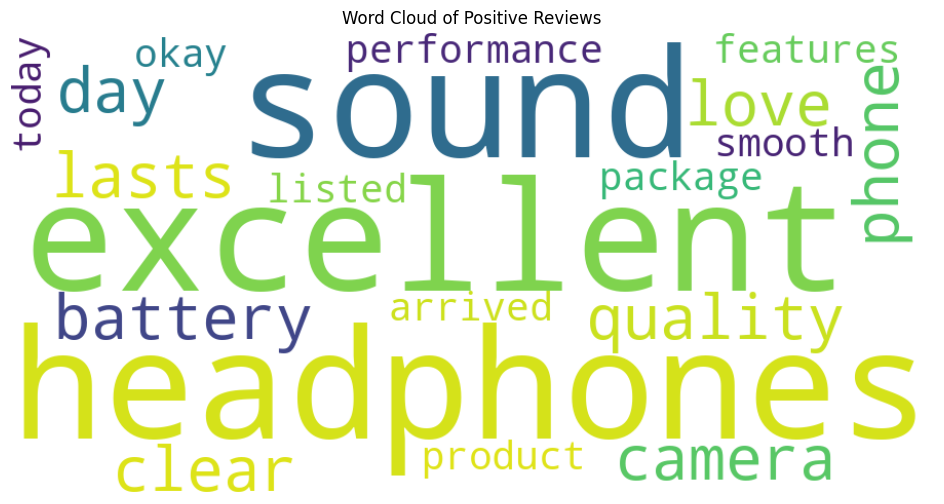

In [16]:
reviews = [
    "The headphones have excellent sound quality and the battery lasts all day.",
    "I love this phone because the camera is clear and the performance is smooth.",
    "The product is disappointing and stopped working after two days.",
    "The delivery was late and customer support was not helpful.",
    "The package arrived today. The product is okay and has the features listed."
]

positive_reviews = []
print("Sentiment analysis results:")
for i, review in enumerate(reviews, 1):
    sentiment = TextBlob(review).sentiment
    polarity = sentiment.polarity
    subjectivity = sentiment.subjectivity

    if polarity > 0:
        label = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        label = "Negative"
    else:
        label = "Neutral"

    print(f"\nReview {i}: {review}")
    print(f"Polarity: {polarity:.3f} | Subjectivity: {subjectivity:.3f} | Class: {label}")

# Word cloud from all positive reviews
if positive_reviews:
    positive_text = " ".join(positive_reviews)
    wordcloud = WordCloud(
        width=900, height=450, background_color="white",
        stopwords=stop_words, collocations=False
    ).generate(positive_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews were detected, so a word cloud cannot be generated.")

## Q6. Text generation using a simple LSTM


In [17]:
training_text = (
    "Technology is changing the way people learn and work. "
    "Digital tools help students access information and practise new skills. "
    "Artificial intelligence can support learning by explaining difficult ideas. "
    "People use computers to communicate, create projects, and solve problems. "
    "Good technology should be useful, safe, and accessible to everyone. "
    "Learning how technology works helps people make better decisions. "
    "In the future, innovation may improve education, healthcare, and transport. "
    "Students can prepare for this future by staying curious and practising regularly. "
    "Technology is most valuable when it helps people and improves everyday life."
)

word_count = len(re.findall(r"\b\w+\b", training_text))
print("Training paragraph word count:", word_count)
print(training_text)

Training paragraph word count: 91
Technology is changing the way people learn and work. Digital tools help students access information and practise new skills. Artificial intelligence can support learning by explaining difficult ideas. People use computers to communicate, create projects, and solve problems. Good technology should be useful, safe, and accessible to everyone. Learning how technology works helps people make better decisions. In the future, innovation may improve education, healthcare, and transport. Students can prepare for this future by staying curious and practising regularly. Technology is most valuable when it helps people and improves everyday life.


In [18]:
# Tokenize using Keras Tokenizer
try:
    from tensorflow.keras.preprocessing.text import Tokenizer
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Embedding, LSTM, Dense
except ImportError:
    from keras.preprocessing.text import Tokenizer
    from keras.preprocessing.sequence import pad_sequences
    from keras.models import Sequential
    from keras.layers import Embedding, LSTM, Dense

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1

input_sequences = []
for sentence in training_text.split("."):
    sentence = sentence.strip()
    if not sentence:
        continue
    token_list = tokenizer.texts_to_sequences([sentence])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i+1])

max_sequence_len = max(len(seq) for seq in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_sequence_len, padding="pre")

X = input_sequences[:, :-1]
y = input_sequences[:, -1]
y = np.eye(total_words)[y]

print("Vocabulary size:", total_words - 1)
print("Number of input sequences:", len(input_sequences))
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Vocabulary size: 70
Number of input sequences: 82
Input shape: (82, 11)
Target shape: (82, 71)


In [19]:
# Build and train a simple LSTM model
model = Sequential([
    Embedding(total_words, 32, input_length=max_sequence_len - 1),
    LSTM(64),
    Dense(total_words, activation="softmax")
])

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
history = model.fit(X, y, epochs=100, verbose=0)

print("Training completed.")
print("Final training loss:", round(history.history["loss"][-1], 4))
print("Final training accuracy:", round(history.history["accuracy"][-1], 4))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Training completed.
Final training loss: 1.5234
Final training accuracy: 0.6951


In [11]:
# Generate 2–3 new lines from a seed phrase
def generate_text(seed_text, next_words=30):
    generated = seed_text

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([generated])[0]
        token_list = pad_sequences(
            [token_list], maxlen=max_sequence_len - 1, padding="pre"
        )
        probabilities = model.predict(token_list, verbose=0)[0]
        predicted_id = int(np.argmax(probabilities))

        output_word = None
        for word, index in tokenizer.word_index.items():
            if index == predicted_id:
                output_word = word
                break

        if output_word is None:
            break
        generated += " " + output_word

    return generated

seed_text = "technology is"
generated_text = generate_text(seed_text, next_words=30)
print("Seed phrase:", seed_text)
print("\nGenerated text:")
print(generated_text)

Seed phrase: technology is

Generated text:
technology is the the way people learn and work improves everyday life life life life regularly regularly life life life life regularly regularly regularly regularly regularly regularly regularly regularly regularly regularly regularly
